In [1]:
from kids.catalog.catalog import load_and_prepare_catalog

In [2]:
df = load_and_prepare_catalog('../data/KiDS_DR5_WCScut_columns_15MLN.csv')
df

,ID,RAJ2000,DECJ2000,MAG_GAAP_u,MAG_GAAP_g,MAG_GAAP_r,MAG_GAAP_i1,MAG_GAAP_i2,MAG_GAAP_Z,MAG_GAAP_Y,...,Z/Y,Z/J,Z/H,Z/Ks,Y/J,Y/H,Y/Ks,J/H,J/Ks,H/Ks
0,KiDSDR5 J121353.971-033201.41,183.474880,-3.533727,24.499487,25.146364,25.316225,NaN,NaN,24.589624,23.379536,...,1.051758,1.078107,1.100143,1.064109,1.025052,1.046004,1.011743,1.020440,0.987016,0.967246
1,KiDSDR5 J091844.652+003808.41,139.686051,0.635672,24.451838,24.399616,23.857410,23.251162,23.194641,23.436424,22.489979,...,1.042083,1.025496,1.024082,NaN,0.984083,0.982726,NaN,0.998621,NaN,NaN
2,KiDSDR5 J134414.817-004040.56,206.061739,-0.677934,23.266325,22.556801,21.644712,21.203636,21.351440,21.118835,20.826136,...,1.014054,1.015042,1.033334,1.042975,1.000974,1.019012,1.028520,1.018021,1.027519,1.009330
3,KiDSDR5 J021614.688-280145.65,34.061200,-28.029349,23.492374,23.211689,22.572300,21.922939,21.910519,21.614155,21.350348,...,1.012356,1.010254,1.024128,1.045779,0.997924,1.011629,1.033015,1.013733,1.035164,1.021140
4,KiDSDR5 J001854.828-331155.41,4.728450,-33.198725,23.718428,23.814079,23.093193,22.505394,22.595203,21.811636,21.781170,...,1.001399,1.035022,1.032046,1.060539,1.033576,1.030604,1.059058,0.997124,1.024653,1.027608
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10881752,KiDSDR5 J135916.715+000423.28,209.819650,0.073135,24.817921,25.745232,24.312620,24.086998,23.790876,23.697920,23.212017,...,1.020933,1.033179,1.028888,1.025338,1.011995,1.007792,1.004314,0.995847,0.992410,0.996549
10881753,KiDSDR5 J023612.988-321017.28,39.054118,-32.171469,24.395250,24.761929,23.373363,23.414555,23.063253,22.575697,22.160776,...,1.018723,1.027666,1.034925,1.056123,1.008779,1.015904,1.036713,1.007063,1.027691,1.020483
10881754,KiDSDR5 J003945.718-272311.81,9.940493,-27.386614,24.306509,24.051279,23.782482,23.281630,23.832741,23.099586,22.695662,...,1.017797,1.016603,1.027385,1.057628,0.998826,1.009419,1.039134,1.010606,1.040356,1.029437
10881755,KiDSDR5 J124503.140-030600.09,191.263086,-3.100027,24.233152,24.251434,23.991739,23.993807,23.929296,23.123039,23.213345,...,0.996110,1.032996,1.029961,NaN,1.037030,1.033984,NaN,0.997062,NaN,NaN


In [3]:
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from kids.features import clf_features

In [4]:
preprocess_features = Pipeline([('imputer', SimpleImputer(missing_values=np.nan, strategy='median')),
                                ('scaler', StandardScaler())])

In [5]:
preprocess_features.fit(df.loc[:, clf_features].sample(2_500_000))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](91,)","['u-g','u-r','u-i1',...,'J/Ks','H/Ks','CLASS_STAR']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,91
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool

In [6]:
features = preprocess_features.transform(df.loc[:, clf_features])

In [7]:
import torch
from torchsom.core import SOM

In [8]:
features = torch.tensor(features, dtype=torch.float32)

In [9]:
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm

class MySOM(SOM):
    def fit(
        self,
        data: torch.Tensor,
        verbose: bool = True,
    ) -> tuple[list[float], list[float]]:
        """Train the SOM using batches and track errors.

        Args:
            data (torch.Tensor): input data tensor [batch_size, num_features]
            verbose (bool, optional): Whether to print progress. Defaults to True.

        Returns:
            Tuple[List[float], List[float]]: Quantization and topographic errors [epoch]
        """
        dataset = TensorDataset(data)
        dataloader = DataLoader(
            dataset,
            batch_size=self.batch_size,
            shuffle=True,
            pin_memory=True,
            num_workers=8,
        )

        epoch_q_errors = []
        epoch_t_errors = []
        for epoch in tqdm(
            range(self.epochs),
            desc="Training SOM",
            unit="epoch",
            disable=not verbose,
        ):
            # Update learning parameters thanks to decay functions (schedulers)
            lr = self.lr_schedule[epoch]
            sigma = self.sigma_schedule[epoch]
            batch_q_errors = []
            batch_t_errors = []
            for batch in dataloader:
                batch_data = batch[0].to(self.device)
                # Rerieve the BMUs [batch_size, 2]
                bmus = self.identify_bmus(batch_data)
                # Update the weights
                self._update_weights(batch_data, bmus, lr, sigma)
                # Calculate batch errors
                batch_q_errors.append(self.quantization_error(batch_data))
                batch_t_errors.append(self.topographic_error(batch_data))
            # Calculate average epoch errors
            epoch_q_errors.append(torch.tensor(batch_q_errors).mean().item())
            epoch_t_errors.append(100 * torch.tensor(batch_t_errors).mean().item())

        return epoch_q_errors, epoch_t_errors

    _VALID_RETRIEVAL_MODES = ("bmu_only", "bmu_neighborhood", "bmu_neighborhood_knn")

In [10]:
som = MySOM(x=50, y=50, num_features=features.size(1), epochs=50, batch_size=1024, learning_rate=0.2, sigma=5.0, device='cuda')
som.initialize_weights(data=features, mode='pca')
q_errors, t_errors = som.fit(data=features)

Training SOM:   0%|          | 0/50 [00:00<?, ?epoch/s]

In [11]:
from torchsom.visualization import SOMVisualizer

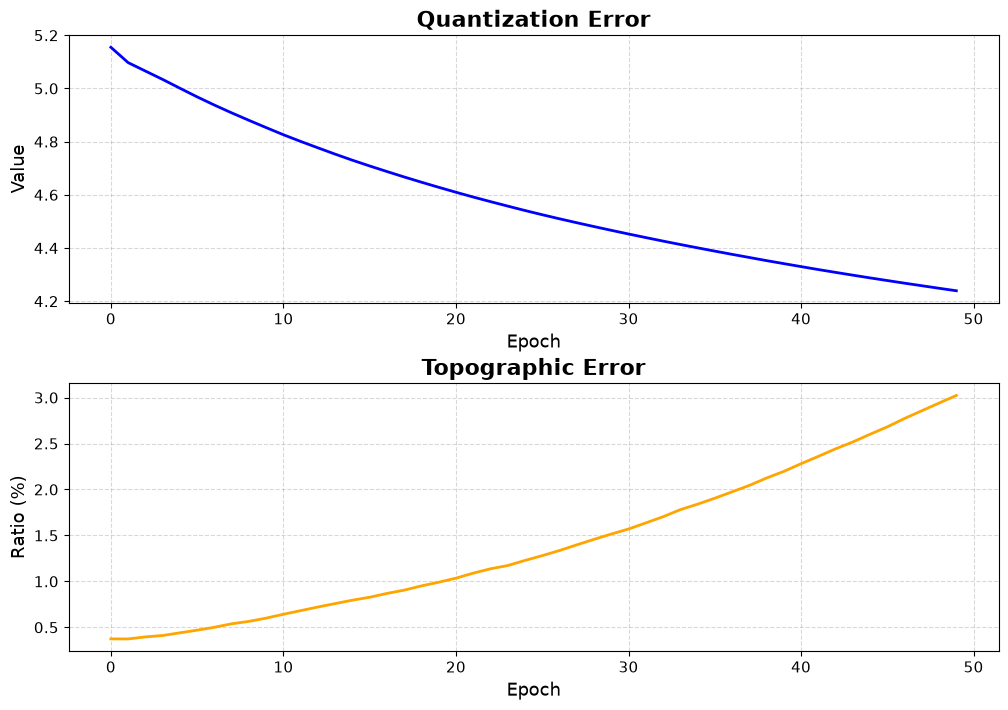

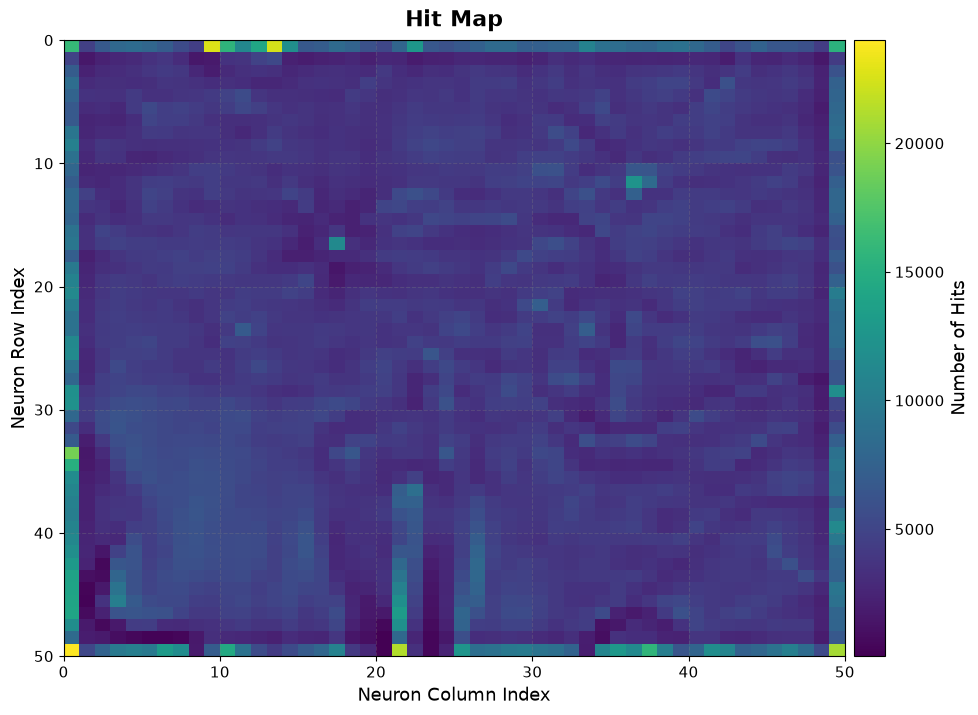

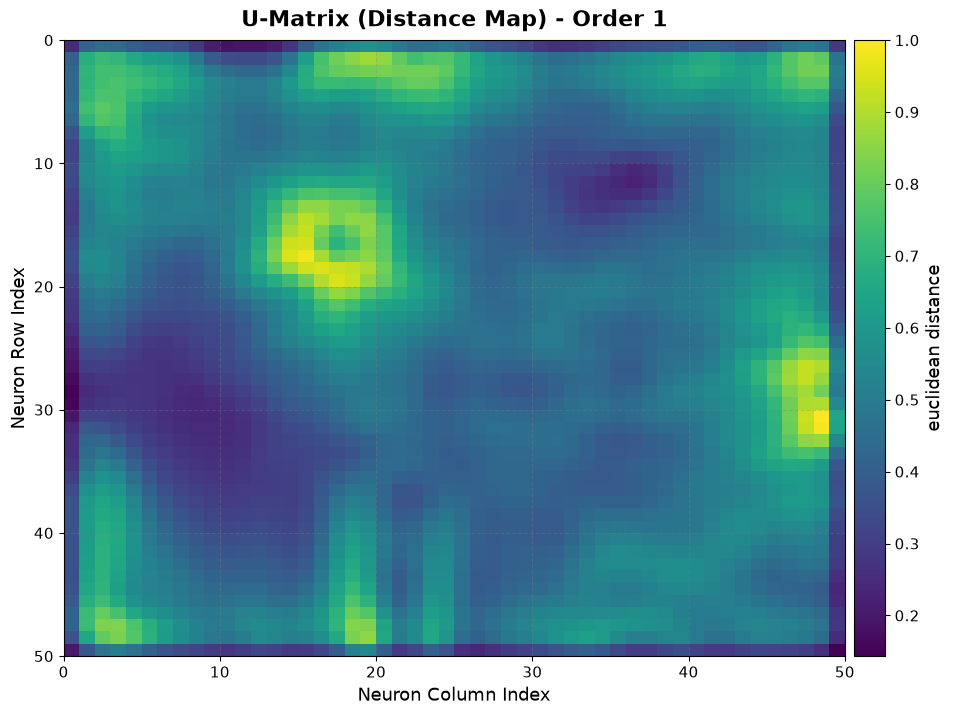

In [12]:
visualizer = SOMVisualizer(som=som)
visualizer.plot_training_errors(quantization_errors=q_errors, topographic_errors=t_errors)
visualizer.plot_hit_map(data=features, batch_size=256)
visualizer.plot_distance_map(
    distance_metric=som.distance_fn_name,
    neighborhood_order=som.neighborhood_order,
    scaling="sum")